# Capstone C4 · A humanoid that follows instructions: Unitree G1 + language-conditioned ACT
"Put the green cube in the bowl." "Pick up the red cube." A Unitree G1 with Dex3 hands (MuJoCo Menagerie) stands at
a table with three cubes and a bowl. It must understand **which** cube, choose the **arm on that side**, and do it,
from its head camera and two wrist cameras (first version: head camera only; it couldn't tell the cubes apart well
enough and ignored the instruction, see the lecture).

**Scope, stated honestly** (these are the parts this capstone does *not* solve):
- the pelvis is **fixed**: no balance control (whole-body loco-manipulation is S16 notebook 151 and an extension);
- grasping uses a **contact-triggered weld**: when the closing hand's grasp point reaches a cube, the cube is attached
  to the hand; opening releases it. The fingers still close visibly. A real 3-finger grasp is a research problem of
  its own (extension 1). Habitat and BEHAVIOR use the same abstraction for the same reason.

What it *does* teach: a two-arm humanoid action space, language grounding with a frozen text encoder (and why HOW
language enters the network matters), action chunking, an evaluation with confidence intervals, and a grounding
test (same scene, different instructions).

In [1]:
import os, json, time, numpy as np, torch, matplotlib.pyplot as plt
from torch.utils.data import Dataset
from vlacourse import show_video, show_images, wilson
from vlacourse import showcase as sc
from vlacourse.chunk_policies import ACT, train_policy
from vlacourse.lang import TextEmbedder, LangChunkRegression
from vlacourse.humanoid import G1Table, G1Expert, G1Film, collect_g1_parallel, COLORS, CAMS
from vlacourse.data import list_episodes, load_episode

device = "cuda" if torch.cuda.is_available() else "cpu"
DATA, H = os.path.join("..", "data", "g1_table_v2"), 20
os.makedirs("checkpoints", exist_ok=True); os.makedirs("results", exist_ok=True)

## 1. The robot and the task
Action (8-D, 10 Hz): move each hand's grasp point by up to 4 cm `[right xyz, left xyz]`, plus an open/close command per
hand. Inverse kinematics on each 7-DoF arm runs inside the environment, like TableTop's end-effector deltas.

instruction: pick up the red cube | state: [ 0.27 -0.22  1.08  0.27  0.22  1.08  0.    0.  ]


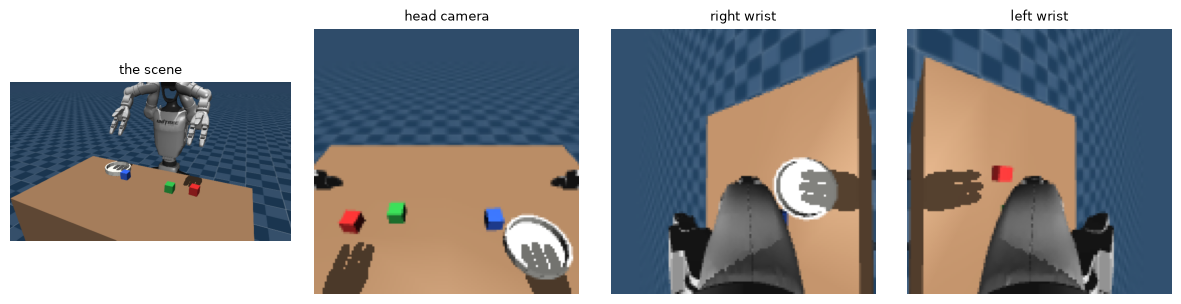

In [2]:
env = G1Table(cameras=CAMS, seed=0)
obs = env.reset(seed=3)
print("instruction:", env.task["instruction"], "| state:", obs["state"].round(2))
show_images([G1Film(env).render()[::2, ::2]] + [obs["images"][c] for c in CAMS], ["the scene", "head camera", "right wrist", "left wrist"], cols=4)

## 2. Demonstrations
A scripted expert picks with the hand on the cube's side; we keep its successful episodes. 400 demos, recorded in
parallel (about a minute with GPU rendering).

In [3]:
if not os.path.exists(f"{DATA}/meta.json"):
    collect_g1_parallel(DATA, 1000, workers=8)
meta = json.load(open(f"{DATA}/meta.json"))
eps = [load_episode(p) for p in list_episodes(DATA)]
print(f"{len(eps)} demos (expert success {meta['expert_success']:.0%}); mean length {np.mean([len(e['action']) for e in eps]):.0f} steps; "
      f"tasks: {sum(e['task']['type'] == 'pick' for e in eps)} pick, {sum(e['task']['type'] == 'place' for e in eps)} place")

1000 demos (expert success 71%); mean length 29 steps; tasks: 535 pick, 465 place


## 3. Language: frozen CLIP text embeddings, trained on paraphrases
The policy never sees raw text: each instruction becomes a 512-D CLIP embedding.
During training every demo is relabelled with a random paraphrase, so the policy learns the *meaning*, not one
sentence. Two phrasings per task are held out for testing.

In [4]:
TRAIN = {"pick": ["pick up the {o} cube", "lift the {o} cube", "grab the {o} cube"],
         "place": ["put the {o} cube in the bowl", "place the {o} cube into the bowl", "move the {o} cube to the bowl"]}
HELDOUT = {"pick": ["raise the {o} block off the table", "could you pick the {o} block up"],
           "place": ["drop the {o} block into the bowl", "the {o} block goes in the bowl"]}
emb = TextEmbedder(device=device)
_ = emb([t.format(o=c) for d in (TRAIN, HELDOUT) for v in d.values() for t in v for c in COLORS])     # cache all

class G1Dataset(Dataset):
    def __init__(self, eps, horizon=H, seed=0):
        self.eps, self.H, self.rng = eps, horizon, np.random.default_rng(seed)
        S, A = np.concatenate([e["state"] for e in eps]), np.concatenate([e["action"] for e in eps])
        self.s_mu, self.s_sd, self.a_mu, self.a_sd = S.mean(0), S.std(0) + 1e-4, A.mean(0), A.std(0) + 1e-4
        self.index = [(i, t) for i, e in enumerate(eps) for t in range(len(e["action"]))]
    def __len__(self):
        return len(self.index)
    def __getitem__(self, k):
        i, t = self.index[k]; e = self.eps[i]; T = len(e["action"]); idx = np.minimum(np.arange(t, t + self.H), T - 1)
        text = self.rng.choice(TRAIN[e["task"]["type"]]).format(o=e["task"]["obj"])
        return {**{c: torch.from_numpy(e[c][t]).permute(2, 0, 1).float() / 255 for c in CAMS},
                "state": torch.tensor((e["state"][t] - self.s_mu) / self.s_sd, dtype=torch.float32),
                "lang": emb([text])[0].float(), "task": emb([text])[0].float(),
                "action": torch.tensor((e["action"][idx] - self.a_mu) / self.a_sd, dtype=torch.float32)}

ds = G1Dataset(eps[:-40])
print(f"{len(ds)} training samples from {len(ds.eps)} demos; 40 demos held out")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

28152 training samples from 960 demos; 40 demos held out


## 4. Two ways to give the policy the instruction, two ways to execute its chunks
**ACT** (S08 74, capstone C2) adds the instruction embedding as one more token next to the image features.
**FiLM** (S09 90) lets the instruction *modulate* every visual feature map (scale and shift per channel), so the
network looks for different things depending on the words. Both predict 20-step (2 s) action chunks.

Execution: **temporal ensembling** (ACT's default) queries every step and averages all overlapping chunks: smooth,
but the average also smears the last centimetres of a reach and makes "close the hand" ramp up slowly.
**Re-planning** executes the first 4 actions of a chunk and then predicts a new one: sharper decisions.

In [5]:
nets = {}
for name, make, lr in [("ACT", lambda: ACT(horizon=H, act_dim=8, cameras=CAMS, state_dim=8, task_dim=emb.dim, kl_weight=10.0), 1e-4),
                       ("FiLM", lambda: LangChunkRegression(lang_dim=emb.dim, horizon=H, act_dim=8, cameras=CAMS, fusion="film"), 3e-4)]:
    net = make(); ckpt = f"checkpoints/g1_{name.lower()}.pt"
    if os.path.exists(ckpt):
        net.load_state_dict(torch.load(ckpt, map_location=device)); net.to(device)
    else:
        t0 = time.time(); train_policy(net, ds, epochs=40, lr=lr, device=device); torch.save(net.state_dict(), ckpt)
        print(f"{name}: trained in {time.time() - t0:.0f}s")
    nets[name] = net.eval()

class G1Policy:
    """replan=None: temporal ensembling (query every step, average overlapping chunks with exp. weights).
    replan=k: execute the first k actions of each chunk, then predict a new chunk."""
    def __init__(self, net, ds, env, instruction_fn=None, replan=None, k=0.01):
        self.net, self.ds, self.env, self.k, self.replan = net, ds, env, k, replan
        self.instruction_fn = instruction_fn or (lambda task: task["instruction"])
    def reset(self):
        self.hist, self.queue = [], []
    @torch.no_grad()
    def _chunk(self, obs):
        e = emb([self.instruction_fn(self.env.task)]).float().to(device)
        b = {**{c: torch.from_numpy(obs["images"][c]).permute(2, 0, 1).float()[None].to(device) / 255 for c in CAMS},
             "state": torch.tensor((obs["state"] - self.ds.s_mu) / self.ds.s_sd, dtype=torch.float32)[None].to(device), "task": e, "lang": e}
        return self.net.sample(b)[0].cpu().numpy() * self.ds.a_sd + self.ds.a_mu
    def act(self, obs):
        if self.replan:
            if not self.queue:
                self.queue = list(self._chunk(obs)[: self.replan])
            return self.queue.pop(0)
        t = self.env.t; self.hist.append((t, self._chunk(obs)))
        preds = [c[t - s] for s, c in self.hist if t - s < self.ds.H]; w = np.exp(-self.k * np.arange(len(preds)))
        self.hist = [(s, c) for s, c in self.hist if t - s < self.ds.H - 1]
        return np.sum([p * wi for p, wi in zip(preds, w)], 0) / w.sum()

def episode(policy, seed, task=None):
    """Runs one episode. Returns (success, the cube the hands got closest to = what the robot WENT FOR)."""
    obs = env.reset(seed=seed)
    if task is not None:
        env.task = task; obs = env.observe()
    policy.reset(); done = False; closest = {c: np.inf for c in COLORS}
    while not done:
        obs, _, done, info = env.step(policy.act(obs))
        for c in COLORS:
            closest[c] = min(closest[c], *(np.linalg.norm(env.hand_pos(s) - env.cube_pos(c)) for s in ("right", "left")))
    return info["success"], min(closest, key=closest.get)

def evaluate_g1(policy, n=40, seed=70_000):
    res = []
    for i in range(n):
        ok, went = episode(policy, seed + i)
        res.append((env.task["type"], ok, went == env.task["obj"]))
    k = sum(r[1] for r in res)
    return dict(success=k / n, ci=wilson(k, n), went_for_named=float(np.mean([r[2] for r in res])),
                per_task={t: float(np.mean([r[1] for r in res if r[0] == t])) for t in ("pick", "place")})

vlacourse/chunk_policies.py:76: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  enc = lambda: nn.TransformerEncoder(nn.TransformerEncoderLayer(d, 8, 4 * d, 0.1, batch_first=True, norm_first=True), layers)


In [6]:
results = {}
for name, net in nets.items():
    for mode, rp in [("temporal ensembling", None), ("re-plan every 4 steps", 4)]:
        t0 = time.time(); results[(name, mode)] = r = evaluate_g1(G1Policy(net, ds, env, replan=rp))
        print(f"{name:5s} {mode:22s} success {r['success']:.0%} (CI {r['ci'][0]:.0%}–{r['ci'][1]:.0%}) | went for the named cube {r['went_for_named']:.0%} "
              f"| pick {r['per_task']['pick']:.0%}, place {r['per_task']['place']:.0%} ({time.time() - t0:.0f}s)")
best = max(results, key=lambda key: results[key]["success"])
net, best_replan = nets[best[0]], (4 if best[1].startswith("re-plan") else None)
held = lambda task: HELDOUT[task["type"]][0].format(o=task["obj"])
r_p = evaluate_g1(G1Policy(net, ds, env, instruction_fn=held, replan=best_replan))
print(f"best: {best[0]} + {best[1]}; unseen phrasings (\"{HELDOUT['pick'][0]}\" ...): success {r_p['success']:.0%}, went for the named cube {r_p['went_for_named']:.0%}")

ACT   temporal ensembling    success 28% (CI 16%–43%) | went for the named cube 85% | pick 30%, place 24% (50s)


ACT   re-plan every 4 steps  success 35% (CI 22%–50%) | went for the named cube 82% | pick 30%, place 41% (33s)


FiLM  temporal ensembling    success 38% (CI 24%–53%) | went for the named cube 100% | pick 39%, place 35% (39s)


FiLM  re-plan every 4 steps  success 57% (CI 42%–71%) | went for the named cube 98% | pick 74%, place 35% (25s)


best: FiLM + re-plan every 4 steps; unseen phrasings ("raise the {o} block off the table" ...): success 22%, went for the named cube 100%


## 5. Is it really listening? The grounding test
One layout, three instructions ("pick up the red / green / blue cube"). A policy that ignored language would go for
the same cube every time. We measure *which cube it goes for* (the cube its hands get closest to) separately from
*whether the grasp succeeds*: the first is about language, the second about precision.

In [7]:
pol = G1Policy(net, ds, env, replan=best_replan)
g = []
for s in range(10):
    row = {}
    for c in COLORS:
        ok, went = episode(pol, 80_000 + s, dict(type="pick", obj=c, instruction=TRAIN["pick"][0].format(o=c)))
        row[c] = (went == c, ok)
    g.append(row)
went = sum(v[0] for d in g for v in d.values()); picked = sum(v[1] for d in g for v in d.values()); total = 3 * len(g)
print(f"grounding (10 layouts × 3 colours): went for the named cube {went}/{total} (chance ≈ {total // 3}), picked it up {picked}/{total}")

grounding (10 layouts × 3 colours): went for the named cube 30/30 (chance ≈ 10), picked it up 13/30


In [8]:
json.dump(dict(policies={f"{k[0]} | {k[1]}": dict(success=v["success"], ci=list(v["ci"]), went_for_named=v["went_for_named"]) for k, v in results.items()},
               best=list(best), paraphrase=r_p["success"], grounding=dict(went_for_named=[went, total], picked=[picked, total])),
          open("results/C4_g1.json", "w"), indent=1)

## 6. Share-ready video
The same table, three instructions, one after the other: the robot chooses the cube *and* the arm.

In [9]:
def film_episode(seed, task, label):
    env.reset(seed=seed); env.task = task
    p = G1Policy(net, ds, env, replan=best_replan); p.reset(); obs = env.observe(); done = False
    env.start_video(size=(720, 1280), fps=50)
    while not done:
        obs, _, done, info = env.step(p.act(obs))
    frames = env.stop_video()
    frames = [sc.caption(f, f"“{task['instruction']}”", where="top", size=30) for f in frames]
    frames = [sc.badge(f, label, corner="tr", size=22) for f in frames]
    end = sc.badge(frames[-1], "✓ done" if info["success"] else "✗ missed the grasp", corner="bl", size=30, color=sc.GOOD if info["success"] else sc.BAD)
    return frames + [end] * 40

score = [sum(v[1] for v in d.values()) for d in g]                  # the layout where most of the three picks worked
seed = 80_000 + int(np.argmax(score))
env.reset(seed=seed)
tasks = [dict(type="pick", obj=c, instruction=TRAIN["pick"][0].format(o=c)) for c in COLORS]
video = sc.title_card("Capstone C4 · Humanoid VLA", f"Unitree G1 + Dex3 hands · {best[0]} language policy\nhead + wrist cameras · MuJoCo (Menagerie)", size=(720, 1280), n=75)
for k, t in enumerate(tasks):
    video += film_episode(seed, t, f"instruction {k + 1}/{len(tasks)}")
show_video(video, fps=50, title="C4 G1 humanoid VLA HD", width=960)
sc.export(video, "outputs/C4_g1_humanoid_vla.mp4", fps=50)

saved outputs/C4_g1_humanoid_vla.mp4  (3.7 MB)


['outputs/C4_g1_humanoid_vla.mp4']

## What the numbers say
The policy **chooses** correctly (the named cube, with the hand on its side) almost every time; most failures are
in the last few centimetres: the hand closes 2–4 cm off and the grasp misses. The choice of execution mode alone
moves success by tens of points, a reminder that a policy is a network *and* the loop that runs it.

How this capstone got here, each step measured: head camera only → success ~30% and the grasp-based grounding test
looked like chance; + balanced pick/place data → no better; + two wrist cameras and 1,000 demos → the trace shows it
goes for the right cube but grasps imprecisely; + re-planning instead of ensembling → the best success above.
Precision is the open problem: see extensions 1 and 5.

## Extensions (pick one for your submission)
1. **A real grasp:** remove the weld (`env._update_grasp = lambda: None`) and make the Dex3 hand hold the cube with
   friction alone: design a pinch posture, check contact forces, measure the scripted success rate.
2. **Both hands:** add "put the red cube in the bowl" when the cube and bowl are on *opposite* sides, a hand-over
   from one hand to the other (C2 does this on ALOHA).
3. **A planner on top:** "clear the table" → a list of instructions from the S11 System-2 LLM.
4. **Balance:** free the pelvis and keep the G1 standing while it reaches (S16 151 shows why joint PD isn't enough).
5. **Precision:** train on relative-target labels (where the hand should be, S06 62) instead of per-step deltas, or add
   a final visual-servoing step on the wrist camera. Measure the miss distance before and after.